Mean Squared Error: 101434798.50566778
R2 Score: 0.9984263636823408


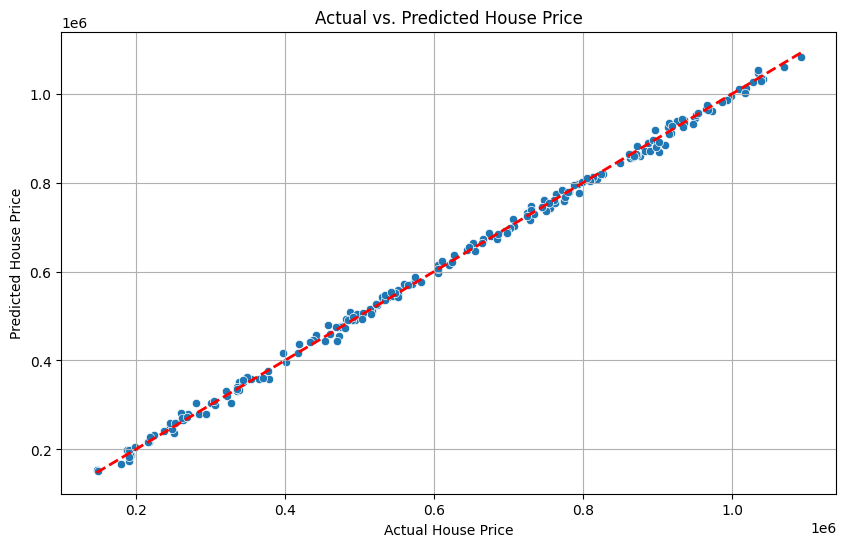

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("house_price_regression_dataset.csv")
df.describe()

X = df[['Square_Footage',
        'Num_Bedrooms',
        'Num_Bathrooms',
        'Year_Built',
        'Lot_Size',
        'Garage_Size',
        'Neighborhood_Quality']]
y = df['House_Price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})
comparison.head()

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Actual', y='Predicted', data=comparison)
plt.title('Actual vs. Predicted House Price')
plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.grid(True)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.show()

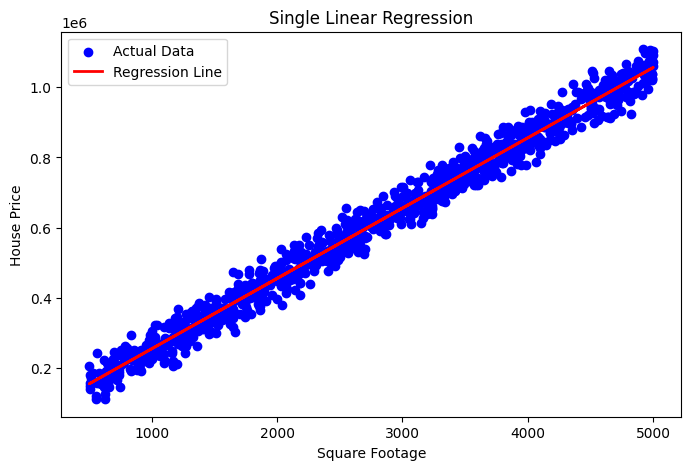

In [4]:
X_single = df[['Square_Footage']]
y = df['House_Price']

single_model = LinearRegression()
single_model.fit(X_single, y)

plt.figure(figsize=(8,5))
plt.scatter(X_single, y, color='blue', label='Actual Data')
plt.plot(X_single, single_model.predict(X_single), color='red', linewidth=2, label='Regression Line')
plt.xlabel("Square Footage")
plt.ylabel("House Price")
plt.title("Single Linear Regression")
plt.legend()
plt.show()